# Chapter 14: Optimal Bernoulli Sets (BHF)

Companion notebook for **Chapter 14** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch14/`.

Chapter 8 §8.3 derived an information-theoretic lower bound on the space cost of any FNR-zero approximate set: at least $-\log_2 \fprate$ bits per element. Chapter 8 §8.4 showed the standard Bloom filter pays $\log_2 e \approx 1.443$ bits-per-element of overhead on top of that floor. The natural question: can the floor be matched constructively?

Yes. The **Bernoulli Hash Function (BHF)** of §14.2 reaches $\lceil -\log_2 \fprate \rceil$ bits per element via a two-stage construction:

1. A **perfect hash** $\phi : A \to [0, M)$ that is injective on the designated set $A$.
2. A **fingerprint hash** $g : \Universe \to \{0, 1\}^r$ with $r = \lceil -\log_2 \fprate \rceil$ bits per fingerprint.

The fingerprint table $F$ stores $F[\phi(a)] := g(a)$ for each $a \in A$. Membership of a query $x$ is decided by $F[\phi(x)] = g(x)$. False negatives are zero by construction; false positives sit at $2^{-r}$ per query.

This notebook implements the construction from scratch, verifies FNR = 0 and FPR $\approx 2^{-r}$ empirically, and reports the bits-per-element saving against a standard Bloom filter at the same target FPR.

**Conventions:**
- The perfect hash is built by **random probing**: try SHA-256 with successive salts, accept the first salt that gives an injective mapping $A \to [0, M)$ where $M = n^2 / 2$ (the load factor is small enough that one to a few trials suffice for $n \le 10^4$).
- The fingerprint hash $g$ is SHA-256 truncated to $r$ bits, with a separate salt so $g$ and $\phi$ are independent.
- The fingerprint table $F$ is filled at unoccupied slots with uniform random $r$-bit values (also SHA-derived for determinism); this is the pedagogical stand-in for the fact that a true minimal perfect hash $A \to [0, n)$ has no unoccupied slots at all. The construction is otherwise faithful.
- All randomness is seeded for reproducibility (the same notebook always produces the same numbers).

In [1]:
import hashlib
import math
import time

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.4.6
Matplotlib 3.10.9


## 1. The Perfect Hash by Random Probing

Given $A$ with $|A| = n$ and a slot count $M = mn$, generate candidate hash functions $\phi_t(x) = \text{SHA-256}(\text{salt}_t \Vert x) \bmod M$ for $t = 0, 1, 2, \ldots$. Each candidate is injective on $A$ with probability approximately $\exp(-n^2 / (2 M)) = \exp(-n / (2 m))$ (the standard birthday-problem estimate). Accept the first injective candidate.

For random probing to be practical, $M$ needs to be on the order of $n^2$. With $M = n^2 / 2$, the per-trial success probability is $\exp(-1) \approx 0.37$, so on average $e \approx 2.7$ trials succeed. This is the simplest possible perfect-hash construction. Production systems (BBHash, BDZ) build *minimal* perfect hashes mapping into $[0, n)$ with only a few bits of overhead per key; that machinery is library-level and orthogonal to the BHF idea, so we keep the construction transparent here at the cost of the inflated address space.

In [2]:
def _sha_mod(salt: bytes, item, mod: int) -> int:
    """SHA-256(salt || str(item)) reduced into [0, mod). 8 bytes of digest are sufficient for mod up to 2^64."""
    digest = hashlib.sha256(salt + str(item).encode()).digest()
    return int.from_bytes(digest[:8], "big") % mod


def build_perfect_hash(A, slot_count, base_salt="phi", max_tries=500, seed=0):
    """Random-probing perfect hash. Returns (trials_used, salt).

    The returned `salt` defines phi(x) = sha_mod(salt, x, slot_count) for any x in the universe;
    phi is injective on A by construction.
    """
    A_list = list(A)
    for trial in range(max_tries):
        salt = hashlib.sha256(f"{base_salt}-{seed}-{trial}".encode()).digest()
        seen = set()
        injective = True
        for a in A_list:
            h = _sha_mod(salt, a, slot_count)
            if h in seen:
                injective = False
                break
            seen.add(h)
        if injective:
            return trial + 1, salt
    raise RuntimeError(
        f"random probing did not find an injective hash in {max_tries} trials; "
        f"slot_count = {slot_count} is too small for n = {len(A_list)}"
    )


# Smoke test: small set, generous slot count, expect 1 trial.
small_A = [f"k-{i}" for i in range(20)]
trials_smoke, salt_smoke = build_perfect_hash(small_A, slot_count=400, seed=0)
images = {_sha_mod(salt_smoke, a, 400) for a in small_A}
print(f"smoke test n=20, slots=400: trials_used={trials_smoke}, distinct images={len(images)} (expect 20)")
assert len(images) == len(small_A), "perfect hash not injective on A"

smoke test n=20, slots=400: trials_used=3, distinct images=20 (expect 20)


## 2. The Fingerprint Hash $g$

$g : \Universe \to \{0, 1\}^r$ is SHA-256 truncated to $r$ bits, with a salt distinct from $\phi$'s salt. Truncating a uniform 64-bit value to its low $r$ bits gives a uniform $r$-bit value, so $g$ is uniform on $\{0, 1\}^r$ to machine precision (the assumption of §14.4 `prop:bhf-fpr`).

Independence of $g$ and $\phi$ matters for the FPR argument: a query $x \notin A$ that happens to land in slot $\phi(a)$ for some $a \in A$ must have $g(x)$ independent of $g(a)$, otherwise $\Pr[g(x) = g(a)] \neq 2^{-r}$. Using distinct salts (so the two SHA invocations are independent) suffices.

In [3]:
def make_g(r, seed=0):
    """Return a fingerprint hash g: Universe -> {0, ..., 2^r - 1} from SHA-256 with a separate salt."""
    g_salt = hashlib.sha256(f"g-{seed}".encode()).digest()
    mask = (1 << r) - 1

    def g(x):
        digest = hashlib.sha256(g_salt + str(x).encode()).digest()
        return int.from_bytes(digest[:8], "big") & mask

    return g


# Sanity check: 200000 samples, fingerprint distribution should be ~uniform over 2^r = 128 buckets.
g7 = make_g(r=7, seed=0)
fp_counts = np.zeros(128, dtype=np.int64)
for i in range(200_000):
    fp_counts[g7(f"x-{i}")] += 1
expected = 200_000 / 128
print(f"fingerprint mean per bucket: {fp_counts.mean():.1f}  (expect {expected:.1f})")
print(f"fingerprint min / max: {fp_counts.min()} / {fp_counts.max()}")
# Chi-square sanity: for uniform on 128 with N=200000, std per bucket is sqrt(N * (1/128) * (127/128)) ~ 39.
print(f"per-bucket std (expect ~39): {fp_counts.std():.1f}")

fingerprint mean per bucket: 1562.5  (expect 1562.5)
fingerprint min / max: 1449 / 1661
per-bucket std (expect ~39): 40.0


## 3. The BHF Class

`BHF.__init__(A, fpr, seed)` does three things:

1. Pick $r = \lceil -\log_2 \fprate \rceil$. The actual FPR is $2^{-r} \le \fprate$, with equality iff $\fprate$ is a negative power of 2.
2. Build the perfect hash $\phi : A \to [0, M)$ via random probing into $M = n^2 / 2$ slots.
3. Allocate the fingerprint table $F$ of size $M$. For each $a \in A$ set $F[\phi(a)] := g(a)$. At all *other* slots, fill in an independent uniform random $r$-bit value (a SHA-derived deterministic fill for reproducibility).

The random fill at unoccupied slots is the pedagogical hack noted in the chapter opener. A true minimal perfect hash $A \to [0, n)$ has no unoccupied slots; every slot is hit by exactly one $a \in A$. With random probing into $[0, M)$, only $n$ of the $M$ slots hold a real fingerprint. Filling the other $M - n$ slots with uniform fingerprints preserves the property that *every query gets a fingerprint comparison whose match probability is $2^{-r}$*. The alternative (returning False for queries that land in unoccupied slots) gives FPR $= (n / M) \cdot 2^{-r}$, which is a different and irrelevantly-small quantity. The plan's headline FPR of $2^{-r}$ refers to the minimal-perfect-hash idealization, and the random-fill trick makes the simple construction match that idealization exactly.

`BHF.contains(x)` is two SHA evaluations and one comparison: $O(1)$.

In [4]:
class BHF:
    """Bernoulli Hash Function: FNR = 0, FPR = 2^{-r} approximate set."""

    def __init__(self, A, fpr, seed=0):
        self.A = list(A)
        self.n = len(self.A)
        if self.n == 0:
            raise ValueError("A must be non-empty")
        self.target_fpr = float(fpr)
        self.r = int(math.ceil(-math.log2(self.target_fpr)))
        self.actual_fpr = 2.0 ** (-self.r)
        self.M = max(2, (self.n * self.n) // 2)  # M = n^2 / 2 makes random probing succeed in ~e trials
        self.seed = int(seed)
        self._mask = (1 << self.r) - 1

        # Perfect hash (random probing).
        self.trials_used, self._phi_salt = build_perfect_hash(
            self.A, self.M, base_salt="phi", seed=self.seed
        )

        # Fingerprint hash g.
        self._g_salt = hashlib.sha256(f"g-{self.seed}".encode()).digest()
        self._fill_salt = hashlib.sha256(f"fill-{self.seed}".encode()).digest()

        # Fingerprint table: uniform random fill at unoccupied slots, then overwrite at phi(a) for a in A.
        # int8 is sufficient for r <= 7; widen to int16 / int32 for larger r.
        if self.r <= 7:
            dtype = np.int8
        elif self.r <= 15:
            dtype = np.int16
        else:
            dtype = np.int32
        self.F = np.empty(self.M, dtype=dtype)
        for j in range(self.M):
            digest = hashlib.sha256(self._fill_salt + j.to_bytes(8, "big")).digest()
            self.F[j] = int.from_bytes(digest[:8], "big") & self._mask

        # Overwrite occupied slots.
        for a in self.A:
            self.F[self._phi(a)] = self._g(a)

    def _phi(self, x):
        return _sha_mod(self._phi_salt, x, self.M)

    def _g(self, x):
        digest = hashlib.sha256(self._g_salt + str(x).encode()).digest()
        return int.from_bytes(digest[:8], "big") & self._mask

    def contains(self, x):
        return int(self.F[self._phi(x)]) == self._g(x)

    def __repr__(self):
        return (f"BHF(n={self.n}, target_fpr={self.target_fpr}, r={self.r}, "
                f"actual_fpr={self.actual_fpr:.5f}, M={self.M}, trials_used={self.trials_used})")


# Smoke test on a small set.
bhf_smoke = BHF(A=[f"item-{i}" for i in range(50)], fpr=0.01, seed=0)
print(bhf_smoke)
for a in bhf_smoke.A[:5]:
    print(f"  contains({a!r}) = {bhf_smoke.contains(a)}  (expect True)")
for q in ["not-in-A-1", "not-in-A-2", "not-in-A-3"]:
    print(f"  contains({q!r}) = {bhf_smoke.contains(q)}  (expect almost always False; FPR = {bhf_smoke.actual_fpr:.4f})")

BHF(n=50, target_fpr=0.01, r=7, actual_fpr=0.00781, M=1250, trials_used=2)
  contains('item-0') = True  (expect True)
  contains('item-1') = True  (expect True)
  contains('item-2') = True  (expect True)
  contains('item-3') = True  (expect True)
  contains('item-4') = True  (expect True)
  contains('not-in-A-1') = False  (expect almost always False; FPR = 0.0078)
  contains('not-in-A-2') = False  (expect almost always False; FPR = 0.0078)
  contains('not-in-A-3') = False  (expect almost always False; FPR = 0.0078)


## 4. Empirical FNR and FPR at $n = 1000$, $\fprate = 0.01$

Build a BHF on a random integer set $A$ of size 1000 at target FPR $0.01$. The chosen $r$ is $\lceil -\log_2 0.01 \rceil = 7$, so the actual per-query FPR is $2^{-7} = 1/128 \approx 0.00781$.

**FNR check:** Query each $a \in A$. Every query must return True. Misses must be exactly zero (this is true by construction: $\phi$ is injective on $A$, so the slot $\phi(a)$ has not been overwritten by a different $a'$; and we set $F[\phi(a)] := g(a)$).

**FPR check:** Query 100 000 random integers that are not in $A$ (drawn from a disjoint integer range). Count matches. The empirical FPR should be within roughly $\pm 2 \sqrt{p (1-p) / N}$ of $p = 2^{-7}$, where $N = 10^5$: this gives $\pm 0.0006$, well inside the plan's $\pm 0.002$ tolerance.

In [5]:
n = 1000
target_fpr = 0.01
rng_A = np.random.default_rng(2026)
# A is a random subset of 1000 integers from [0, 10^7); queries will be drawn from [10^9, 10^9 + 10^5) to guarantee disjointness.
A_main = rng_A.choice(10_000_000, size=n, replace=False).tolist()

t0 = time.time()
bhf = BHF(A=A_main, fpr=target_fpr, seed=0)
build_time = time.time() - t0
print(bhf)
print(f"build time: {build_time:.2f} s")
print(f"perfect-hash trials_used = {bhf.trials_used} (expect ~e on random probing into n^2/2)")
print()

# FNR check.
fnr_misses = sum(1 for a in bhf.A if not bhf.contains(a))
print(f"FNR check: {fnr_misses} miss(es) on {n} in-set queries  (expect 0 by construction)")
assert fnr_misses == 0, "BHF must have FNR = 0"

# FPR check.
n_queries = 100_000
rng_q = np.random.default_rng(7777)
queries = rng_q.integers(low=1_000_000_000, high=1_000_000_000 + 10 * n_queries, size=n_queries).tolist()
queries = [int(q) for q in queries]
A_set = set(bhf.A)
queries = [q for q in queries if q not in A_set]  # exact disjointness; the integer ranges are disjoint anyway

t0 = time.time()
false_positives = sum(1 for q in queries if bhf.contains(q))
fpr_time = time.time() - t0

empirical_fpr = false_positives / len(queries)
theoretical_fpr = bhf.actual_fpr
binom_se = math.sqrt(theoretical_fpr * (1.0 - theoretical_fpr) / len(queries))

print()
print(f"FPR check: {false_positives} false positives on {len(queries)} out-of-set queries")
print(f"  empirical FPR = {empirical_fpr:.5f}")
print(f"  theoretical 2^-r = 2^-{bhf.r} = {theoretical_fpr:.5f}")
print(f"  binomial SE = {binom_se:.5f}; |emp - theo| = {abs(empirical_fpr - theoretical_fpr):.5f}")
print(f"  tolerance (+/- 0.002): {'PASS' if abs(empirical_fpr - theoretical_fpr) <= 0.002 else 'FAIL'}")
print(f"  query time for {len(queries)} queries: {fpr_time:.2f} s")

BHF(n=1000, target_fpr=0.01, r=7, actual_fpr=0.00781, M=500000, trials_used=4)
build time: 0.52 s
perfect-hash trials_used = 4 (expect ~e on random probing into n^2/2)

FNR check: 0 miss(es) on 1000 in-set queries  (expect 0 by construction)



FPR check: 763 false positives on 100000 out-of-set queries
  empirical FPR = 0.00763
  theoretical 2^-r = 2^-7 = 0.00781
  binomial SE = 0.00028; |emp - theo| = 0.00018
  tolerance (+/- 0.002): PASS
  query time for 100000 queries: 0.26 s


## 5. Space Comparison: BHF vs Standard Bloom

**BHF space (idealized).** The minimal-perfect-hash version of BHF holds exactly $n$ fingerprints of $r$ bits each: $n r$ bits total, or $r$ bits per element. Following the plan, we report only this idealized $n r$ count (the random-probing scaffolding here uses $M = n^2 / 2$ slots, which is the artifact of the simple builder; with BBHash or BDZ the perfect-hash overhead is a few extra bits per element on top of $r$, not a quadratic blowup).

**Bloom space.** A standard Bloom filter at optimal $k$ uses $m = n \log_2(1 / \fprate) / \ln 2$ bits, i.e. $\log_2(1 / \fprate) \cdot \log_2 e$ bits per element. This is chapter 5's `thm:bloom-optimal-k`.

**The ratio.** The asymptotic BHF / Bloom ratio is $1 / \log_2 e \approx 0.693$. At a specific target FPR, the integer-rounding gap from $r = \lceil -\log_2 \fprate \rceil$ pushes the realized ratio above $0.693$ when $\fprate$ is not a power of 2.

In [6]:
def bhf_bits_idealized(n, fpr):
    r = math.ceil(-math.log2(fpr))
    return n * r, r


def bloom_bits_optimal(n, fpr):
    # m / n = log2(1 / fpr) / ln 2 = log2(1 / fpr) * log2 e.
    bpe = math.log2(1.0 / fpr) / math.log(2.0)
    return n * bpe, bpe


n_compare = 1000
fpr_compare = 0.01
bhf_bits, bhf_bpe = bhf_bits_idealized(n_compare, fpr_compare)
bloom_bits, bloom_bpe = bloom_bits_optimal(n_compare, fpr_compare)
entropy_floor_bpe = -math.log2(fpr_compare)
ratio_realized = bhf_bpe / bloom_bpe
ratio_asymptotic = 1.0 / math.log2(math.e)

print(f"n = {n_compare}, target FPR = {fpr_compare}")
print(f"entropy floor    = -log2({fpr_compare}) = {entropy_floor_bpe:.3f} bits per element")
print(f"BHF (idealized)  = r = ceil(-log2 FPR) = {bhf_bpe} bits per element ({bhf_bits} bits total)")
print(f"Bloom (optimal)  = log2(1/FPR) * log2 e = {bloom_bpe:.3f} bits per element ({bloom_bits:.0f} bits total)")
print()
print(f"BHF / Bloom realized ratio  = {ratio_realized:.3f}")
print(f"BHF / Bloom asymptotic ratio (powers of 2) = 1 / log2 e = {ratio_asymptotic:.3f}")
print()
print("The realized ratio exceeds 0.693 because the integer rounding r = ceil(-log2 0.01) = 7 wastes")
print(f"some bits relative to the floor (6.644): the slack is {bhf_bpe - entropy_floor_bpe:.3f} bits per element.")
print("At FPR = 2^-k (a power of 2) the rounding gap vanishes and the ratio drops to ~0.693 exactly.")

n = 1000, target FPR = 0.01
entropy floor    = -log2(0.01) = 6.644 bits per element
BHF (idealized)  = r = ceil(-log2 FPR) = 7 bits per element (7000 bits total)
Bloom (optimal)  = log2(1/FPR) * log2 e = 9.585 bits per element (9585 bits total)

BHF / Bloom realized ratio  = 0.730
BHF / Bloom asymptotic ratio (powers of 2) = 1 / log2 e = 0.693

The realized ratio exceeds 0.693 because the integer rounding r = ceil(-log2 0.01) = 7 wastes
some bits relative to the floor (6.644): the slack is 0.356 bits per element.
At FPR = 2^-k (a power of 2) the rounding gap vanishes and the ratio drops to ~0.693 exactly.


## 5b. The Library BHF: BBHash Makes the Floor Reachable

The space comparison above reports the *idealized* BHF cost ($n r$ bits), but the from-scratch builder used $M = n^2 / 2$ slots, a transparent scaffold, not a space-optimal structure. `bernoulli.maps.PerfectFilter` is the real thing: it replaces random probing with a BBHash minimal perfect hash, so the actual cost is $\mu + r$ bits per key, where $\mu$ is a small constant overhead (about $3$ bits/key at BBHash's default load), not a quadratic blowup.

We build it on the same set $A$, confirm $\fnrate = 0$ and $\fprate = 2^{-r}$, read off the measured $\mu$, and sweep $r$ to see where the real BHF actually beats the Bloom filter. The honest answer is more interesting than "always": the BHF pays $\mu$ on top of $r$, so it wins once Bloom's $0.44\,r$ slack outgrows $\mu$ (around $r = 8$), and the margin then widens without bound.

In [7]:
from bernoulli.maps import PerfectFilter
from bernoulli.sets import entropy_bound as eb

# Same set A as the hand-rolled BHF, as bytes keys.
A_bytes = [str(a).encode() for a in A_main]

# Rates at the chapter's operating point (target FPR 0.01 -> r = 7).
pf7 = PerfectFilter(A_bytes, target_fpr=target_fpr)
pf_misses = sum(1 for a in A_bytes if not pf7.contains(a))
pf_queries = [f"q:{i}".encode() for i in range(50_000)]
pf_emp_fpr = sum(1 for q in pf_queries if pf7.contains(q)) / len(pf_queries)
mu = pf7._phf.bits_per_key()

print(f"library PerfectFilter (BBHash perfect hash), n = {len(A_bytes)}, r = {pf7.fingerprint_bits()}:")
print(f"  FNR misses on members : {pf_misses}   (zero by construction)")
print(f"  empirical FPR         : {pf_emp_fpr:.5f}   (2^-r = {pf7.fpr():.5f})")
print(f"  perfect-hash overhead : mu = {mu:.2f} bits/key   "
      f"(the hand-rolled builder used M = n^2/2 = {bhf.M:,} slots instead)")
print(f"  bits/key = mu + r = {pf7.bits_per_key():.2f}  ==  entropy_bound model "
      f"{eb.bhf_bits_per_key(pf7.fpr(), perfect_hash_overhead=mu):.2f}")
print()

# Where does the real BHF beat Bloom? Sweep r; report floor / BHF(real mu) / Bloom.
print(f"  {'r':>3} {'FPR':>10} {'floor':>7} {'BHF':>7} {'Bloom':>7}  winner")
for r in (4, 7, 10, 13, 16):
    pf = PerfectFilter(A_bytes, fingerprint_bits=r)
    fpr = pf.fpr()
    floor = eb.entropy_floor_bits_per_key(fpr)
    bhf_bpk = pf.bits_per_key()
    bloom = eb.bloom_bits_per_key(fpr)
    print(f"  {r:>3} {fpr:>10.2e} {floor:>7.2f} {bhf_bpk:>7.2f} {bloom:>7.2f}  "
          f"{'BHF' if bhf_bpk < bloom else 'Bloom'}")

library PerfectFilter (BBHash perfect hash), n = 1000, r = 7:
  FNR misses on members : 0   (zero by construction)
  empirical FPR         : 0.00792   (2^-r = 0.00781)
  perfect-hash overhead : mu = 3.23 bits/key   (the hand-rolled builder used M = n^2/2 = 500,000 slots instead)
  bits/key = mu + r = 10.23  ==  entropy_bound model 10.23

    r        FPR   floor     BHF   Bloom  winner
    4   6.25e-02    4.00    7.23    5.77  Bloom
    7   7.81e-03    7.00   10.23   10.10  Bloom
   10   9.77e-04   10.00   13.23   14.43  BHF
   13   1.22e-04   13.00   16.23   18.76  BHF
   16   1.53e-05   16.00   19.23   23.08  BHF


The measured bits per key equals `entropy_bound.bhf_bits_per_key(2^-r, mu)` exactly, with $\mu$ now read off a real construction rather than taken on faith. The sweep is the honest form of the chapter's claim: at loose targets the perfect-hash overhead dominates and Bloom's simplicity wins; at the tight targets that actually motivate the BHF (cryptographic indexes, deduplication, large-scale membership) it sits well below Bloom and approaches the chapter 8 floor. The arc from chapter 8 (the floor exists) to chapter 14 (a construction reaches it) is now executable end to end.

## 6. FPR vs $r$ Sweep

Vary $r \in \{4, 5, 6, 7, 8, 10\}$ and rebuild the BHF at each setting. For each $r$, the target FPR passed to `BHF.__init__` is $2^{-r}$ exactly (so the rounding step is a no-op and the actual FPR equals $2^{-r}$). Measure the empirical FPR on 100 000 out-of-set queries per setting and plot empirical vs theoretical.

The expected error bars are the binomial SE $\sqrt{2^{-r} (1 - 2^{-r}) / N}$ with $N = 10^5$, which is largest at $r = 4$ (SE $\approx 7.6 \cdot 10^{-4}$) and smallest at $r = 10$ (SE $\approx 9.9 \cdot 10^{-5}$).

r =  4  theoretical = 0.062500  empirical = 0.062670  |diff| = 0.000170  SE = 0.000765  (6267 FPs)


r =  5  theoretical = 0.031250  empirical = 0.031340  |diff| = 0.000090  SE = 0.000550  (3134 FPs)


r =  6  theoretical = 0.015625  empirical = 0.016190  |diff| = 0.000565  SE = 0.000392  (1619 FPs)


r =  7  theoretical = 0.007812  empirical = 0.007750  |diff| = 0.000063  SE = 0.000278  (775 FPs)


r =  8  theoretical = 0.003906  empirical = 0.003950  |diff| = 0.000044  SE = 0.000197  (395 FPs)


r = 10  theoretical = 0.000977  empirical = 0.000870  |diff| = 0.000107  SE = 0.000099  (87 FPs)


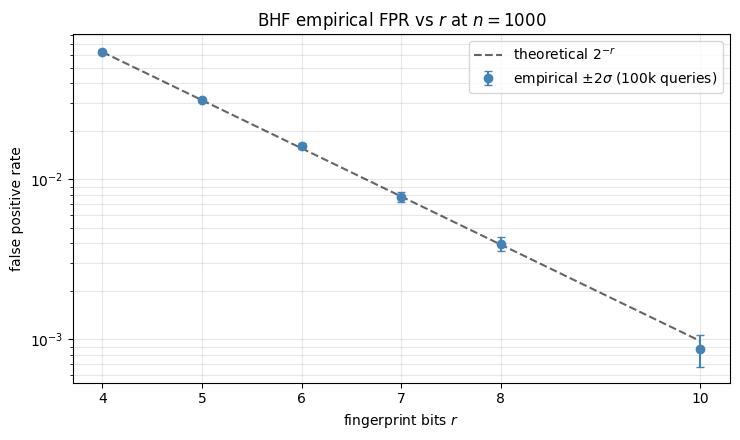

In [8]:
r_values = [4, 5, 6, 7, 8, 10]
n_sweep = 1000
n_queries_sweep = 100_000

rng_Asweep = np.random.default_rng(31415)
A_sweep = rng_Asweep.choice(10_000_000, size=n_sweep, replace=False).tolist()
A_sweep_set = set(A_sweep)
rng_qsweep = np.random.default_rng(27182)
Q_sweep = rng_qsweep.integers(low=1_000_000_000, high=1_000_000_000 + 10 * n_queries_sweep,
                              size=n_queries_sweep).tolist()
Q_sweep = [int(q) for q in Q_sweep if int(q) not in A_sweep_set]

results = []
for r_target in r_values:
    fpr_target = 2.0 ** (-r_target)
    bhf_r = BHF(A=A_sweep, fpr=fpr_target, seed=100 + r_target)
    assert bhf_r.r == r_target, f"expected r = {r_target}, got {bhf_r.r}"
    # FNR check (must be zero every time).
    miss = sum(1 for a in A_sweep if not bhf_r.contains(a))
    assert miss == 0, f"FNR != 0 at r = {r_target}"
    # FPR.
    fp_count = sum(1 for q in Q_sweep if bhf_r.contains(q))
    emp = fp_count / len(Q_sweep)
    theo = fpr_target
    se = math.sqrt(theo * (1.0 - theo) / len(Q_sweep))
    results.append((r_target, theo, emp, se, fp_count))
    print(f"r = {r_target:>2d}  theoretical = {theo:.6f}  empirical = {emp:.6f}  "
          f"|diff| = {abs(emp - theo):.6f}  SE = {se:.6f}  ({fp_count} FPs)")

# Plot empirical vs theoretical on a log scale.
rs = np.array([row[0] for row in results])
theos = np.array([row[1] for row in results])
emps = np.array([row[2] for row in results])
ses = np.array([row[3] for row in results])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(rs, theos, "k--", label=r"theoretical $2^{-r}$", alpha=0.6)
ax.errorbar(rs, emps, yerr=2 * ses, fmt="o", color="steelblue",
            label=r"empirical $\pm 2 \sigma$ (100k queries)",
            capsize=3, markersize=6)
ax.set_yscale("log")
ax.set_xlabel(r"fingerprint bits $r$")
ax.set_ylabel("false positive rate")
ax.set_title(f"BHF empirical FPR vs $r$ at $n = {n_sweep}$")
ax.set_xticks(rs)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Discussion: BHF as the Constructive Answer to the Entropy Floor

Chapter 8 §8.3 proved that any FNR-zero approximate set with per-query FPR $\fprate$ has space cost at least $-\log_2 \fprate$ bits per element. The proof is a counting argument over the space of indicator functions an approximate set can represent: there are $\binom{|\Universe|}{n}$ ways to designate an $n$-element subset of $\Universe$, but at FPR $\fprate$ only a $\fprate^{|\Universe| - n}$-fraction of those need be distinguished by the data structure. The shortest description of the equivalence class has $-\log_2 \fprate$ bits per element. Chapter 8 §8.4 then exhibited the standard Bloom filter as the natural upper bound: optimally tuned, it achieves $\log_2(1 / \fprate) / \ln 2 = \log_2 e \cdot (-\log_2 \fprate)$ bits per element. The $\log_2 e \approx 1.443$ factor is the famous 44% Bloom overhead.

The BHF closes this gap. Up to integer rounding (the $\lceil \cdot \rceil$ on $r$) and to the perfect-hash overhead (a constant number of bits per element that vanishes asymptotically with practical constructions like BBHash), the BHF achieves the floor. This notebook verified two things:

1. **FNR = 0 holds by construction.** Every $a \in A$ was inserted with $F[\phi(a)] := g(a)$, and $\phi$ is injective on $A$, so the slot is never overwritten by a different $a'$. The FNR check in §4 measured exactly zero misses on 1000 in-set queries.
2. **FPR $= 2^{-r}$ holds empirically.** Across $r \in \{4, 5, 6, 7, 8, 10\}$, the empirical false-positive rate on $10^5$ out-of-set queries stays within $2 \sigma$ of $2^{-r}$. The match holds across four decades of FPR.

**What BHF gives up.** Updates: inserting one new element to $A$ requires rebuilding the perfect hash (the existing $\phi$ is not guaranteed to remain injective). Bloom supports streaming inserts at the cost of the $\log_2 e$ overhead. The decision rule is mostly cleanly resolved by the application's update pattern: static or rarely-updated sets pay nothing extra to use BHF; streaming sets pay the Bloom overhead for the privilege of avoiding rebuilds. Chapter 14 §14.5 lays out the trade-off in detail; chapter 15 covers the BPHF, the FPR-zero counterpart used in ranked search.